# IS353 - Lab 6b: Graph Learning và Embeddings

**MSSV:** 23520588

Hai cách học vector cho đỉnh:

- **Node2Vec (shallow):** mỗi đỉnh có một vector riêng, học bằng skip-gram trên các random walk. Chỉ dùng cấu trúc đồ thị.
- **GCN (deep):** vector của đỉnh tính từ feature của chính nó và của hàng xóm qua các lớp message passing. Dùng cả feature lẫn cấu trúc, học có giám sát theo nhãn.

Dữ liệu: Karate Club (34 đỉnh) để xem Node2Vec và ảnh hưởng của p, q; Cora (2708 bài báo, 7 chủ đề, 1433 feature bag-of-words) để so Node2Vec với GCN. Phần mở rộng thử GraphSAGE, GAT và link prediction bằng embedding trên ego-Facebook.

Môi trường chạy: torch 2.10 (CPU), torch-geometric 2.7.0, pyg-lib, torch-cluster. Node2Vec của PyG dùng pyg-lib khi p = q = 1. Khi p hoặc q khác 1 thì nó cần torch-cluster.

So với notebook mẫu, có mấy chỗ sửa:

1. Notebook mẫu gọi `n2v.train_epoch(...)`, nhưng PyG không có hàm này. Ở đây viết vòng train bằng `model.loss(pos_rw, neg_rw)`.
2. Notebook mẫu chạy GCN 20000 epoch và in mỗi 20 epoch (1000 dòng). Ở đây ghi lại accuracy từng epoch, vẽ đường cong, và chọn mô hình theo val accuracy.
3. Các biểu đồ t-SNE tô màu theo nhãn thật để so độ tách cụm. Node2Vec được chạy cả trên Cora để so với GCN trên cùng dữ liệu.
4. Node2Vec dùng embedding dense với `Adam` thay cho `sparse=True` + `SparseAdam`. Đồ thị ở đây nhỏ (nhiều nhất vài nghìn đỉnh), bảng embedding chỉ vài MB, và trên CPU bản dense nhanh hơn khoảng 2.6 lần, cho cùng kết quả.
5. Karate chỉ có 34 đỉnh. Với `batch_size=128` như notebook mẫu, mỗi epoch chỉ có một bước cập nhật, 50 epoch là 50 bước, chưa đủ để học. Ở đây dùng `batch_size=8` (5 bước mỗi epoch).

## Cài thư viện

In [1]:
# Cài một lần (CPU). Node2Vec với p, q khác 1 cần torch-cluster, wheel lấy ở data.pyg.org.
# %pip install torch==2.10.0 --index-url https://download.pytorch.org/whl/cpu
# %pip install torch-geometric==2.7.0
# %pip install pyg-lib torch-cluster -f https://data.pyg.org/whl/torch-2.10.0+cpu.html
%pip install -q networkx matplotlib scikit-learn pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: D:\Study\IS353\BT\.venv\Scripts\python.exe -m pip install --upgrade pip


## Import

In [2]:
%matplotlib inline

import warnings
warnings.filterwarnings("ignore", message=".*IProgress.*")

import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import torch_geometric
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from scipy.stats import spearmanr
from sklearn.metrics import adjusted_rand_score, roc_auc_score, average_precision_score, silhouette_score
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from torch_geometric.datasets import KarateClub, Planetoid
from torch_geometric.nn import GATConv, GCNConv, Node2Vec, SAGEConv
from torch_geometric.utils import to_networkx

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 150,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.grid": True,
})
pd.set_option("display.precision", 3)

device = torch.device("mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu"))
print("torch", torch.__version__, "| torch_geometric", torch_geometric.__version__, "| device", device.type)

torch 2.10.0+cpu | torch_geometric 2.7.0 | device cpu


## Hàm dùng chung

- `set_seed`: cố định seed của random, numpy, torch để chạy lại ra cùng số.
- `train_node2vec`: train Node2Vec, trả về embedding và loss từng epoch.
- `tsne_plot`: t-SNE 2 chiều, tô màu theo nhãn.
- `probe_accuracy`: logistic regression trên embedding (train trên tập train, đo trên tập test).

In [3]:
def lab_dir() -> Path:
    candidates = [
        Path.cwd(),
        Path.cwd() / "BT" / "Lab6b",
        Path(r"d:/Study/IS353/BT/Lab6b"),
    ]
    for folder in candidates:
        if (folder / "requirement.txt").exists() and "Lab6b" in str(folder):
            return folder
    raise FileNotFoundError("Không thấy requirement.txt của Lab 6b.")


LAB = lab_dir()
FIG = LAB / "figures"
FIG.mkdir(exist_ok=True)
DATA = LAB / "data"


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def train_node2vec(edge_index, num_nodes, embedding_dim=64, walk_length=10, context_size=5,
                   walks_per_node=5, num_negative_samples=5, p=1.0, q=1.0,
                   epochs=50, lr=0.01, batch_size=128, seed=0, log_every=None, sparse=False):
    set_seed(seed)
    model = Node2Vec(
        edge_index, embedding_dim=embedding_dim, walk_length=walk_length,
        context_size=context_size, walks_per_node=walks_per_node,
        num_negative_samples=num_negative_samples, p=p, q=q,
        num_nodes=num_nodes, sparse=sparse,
    ).to(device)
    loader = model.loader(batch_size=batch_size, shuffle=True)
    if sparse:
        optimizer = torch.optim.SparseAdam(list(model.parameters()), lr=lr)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for pos_rw, neg_rw in loader:
            optimizer.zero_grad()
            loss = model.loss(pos_rw.to(device), neg_rw.to(device))
            loss.backward()
            optimizer.step()
            total += loss.item()
        losses.append(total / len(loader))
        if log_every and epoch % log_every == 0:
            print(f"Epoch {epoch:03d} | Loss {losses[-1]:.4f}")
    model.eval()
    with torch.no_grad():
        z = model().detach().cpu().numpy()
    return z, losses


def tsne_2d(emb, perplexity=30, seed=0):
    return TSNE(n_components=2, init="pca", learning_rate="auto",
                perplexity=perplexity, random_state=seed).fit_transform(emb)


def tsne_plot(ax, xy, labels, title, names=None, annotate=False):
    labels = np.asarray(labels)
    cmap = plt.get_cmap("tab10")
    for c in np.unique(labels):
        m = labels == c
        lab = names[c] if names is not None else str(c)
        ax.scatter(xy[m, 0], xy[m, 1], s=40 if annotate else 6, color=cmap(int(c) % 10), label=lab)
    if annotate:
        for i, (x, y) in enumerate(xy):
            ax.annotate(str(i), (x, y), fontsize=7, ha="center", va="center")
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])


def probe_accuracy(emb, y, train_mask, test_mask):
    scaler = StandardScaler().fit(emb[train_mask])
    clf = LogisticRegression(max_iter=3000).fit(scaler.transform(emb[train_mask]), y[train_mask])
    return clf.score(scaler.transform(emb[test_mask]), y[test_mask])

## 1. Datasets

`KarateClub` của PyG có 4 nhãn (chia cộng đồng theo modularity). Để so với sự kiện thật, mình lấy thêm nhãn hai phe (Mr. Hi và Officer) từ `networkx`. Hai bên đánh số đỉnh giống nhau, từ 0 đến 33.

In [4]:
karate = KarateClub()
data_karate = karate[0].to(device)

cora = Planetoid(root=str(DATA / "Cora"), name="Cora")
data_cora = cora[0].to(device)

print("Karate:", data_karate)
print("Cora:", data_cora)
print(f"Cora: {cora.num_classes} classes, train/val/test = "
      f"{int(data_cora.train_mask.sum())}/{int(data_cora.val_mask.sum())}/{int(data_cora.test_mask.sum())}")

club_attr = nx.get_node_attributes(nx.karate_club_graph(), "club")
club = np.array([0 if club_attr[i] == "Mr. Hi" else 1 for i in range(34)])
CLUB_NAMES = {0: "Mr. Hi", 1: "Officer"}
CORA_NAMES = {i: n for i, n in enumerate(["Theory", "RL", "Genetic Alg.", "Neural Nets",
                                            "Prob. Methods", "Case Based", "Rule Learning"])}
y_cora = data_cora.y.cpu().numpy()
train_mask = data_cora.train_mask.cpu().numpy()
val_mask = data_cora.val_mask.cpu().numpy()
test_mask = data_cora.test_mask.cpu().numpy()
print("Karate clubs:", np.bincount(club), "| Cora class sizes:", np.bincount(y_cora))

Karate: Data(x=[34, 34], edge_index=[2, 156], y=[34], train_mask=[34])
Cora: Data(x=[2708, 1433], edge_index=[2, 10556], y=[2708], train_mask=[2708], val_mask=[2708], test_mask=[2708])
Cora: 7 classes, train/val/test = 140/500/1000
Karate clubs: [17 17] | Cora class sizes: [351 217 418 818 426 298 180]


## 2. Node2Vec trên Karate Club

Tham số như notebook mẫu: embedding 64 chiều, walk dài 10, context 5, mỗi đỉnh 5 walk, 5 negative sample, p = q = 1, 50 epoch. Chỉ đổi `batch_size` thành 8.

In [5]:
emb_karate, loss_karate = train_node2vec(
    data_karate.edge_index, data_karate.num_nodes,
    embedding_dim=64, walk_length=10, context_size=5, walks_per_node=5,
    num_negative_samples=5, p=1.0, q=1.0, epochs=50, batch_size=8, seed=0, log_every=10,
)
print(emb_karate.shape)
emb_karate[:3, :6]

Epoch 010 | Loss 2.7955
Epoch 020 | Loss 2.0533


Epoch 030 | Loss 2.0414
Epoch 040 | Loss 1.9892


Epoch 050 | Loss 1.9828
(34, 64)


array([[ 0.19442041,  0.72726226, -0.6307482 , -0.43852893, -1.1133549 ,
        -0.44382882],
       [-0.6193781 ,  0.53532916,  0.12000438, -0.0339793 ,  0.78498304,
         0.65081847],
       [-0.22246578, -0.17649212, -0.81736165,  0.8175732 , -1.1929581 ,
        -1.1851606 ]], dtype=float32)

## 3. Xem embedding của Node2Vec

Bên trái là đồ thị gốc, bên phải là t-SNE của embedding (perplexity 10, vì chỉ có 34 điểm). Màu là phe thật sau khi câu lạc bộ tách. Thêm ba con số:

- silhouette theo phe (khoảng cách cosine), từ -1 đến 1, càng cao thì hai phe càng tách;
- accuracy của logistic regression đoán phe, cross-validation 5 fold;
- ARI giữa KMeans (k = 2, chạy trên vector đã chuẩn hóa độ dài, tức theo cosine) và phe thật. ARI = 1 là khớp hoàn toàn, 0 là như đoán ngẫu nhiên.

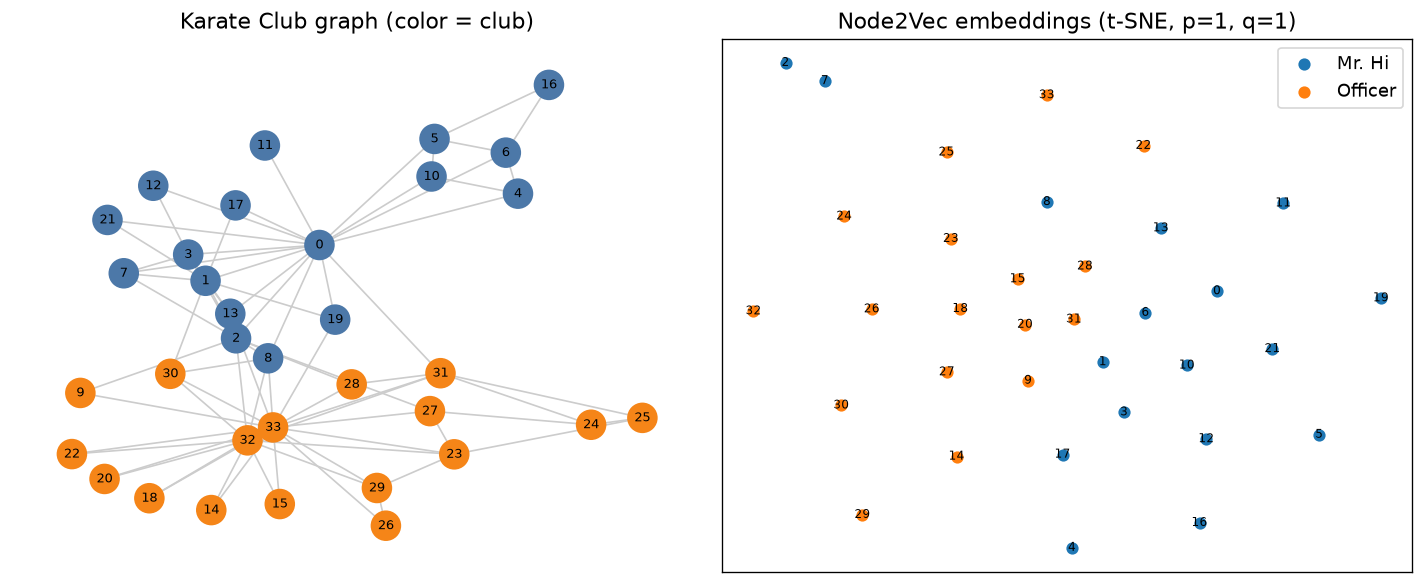

silhouette(club) = 0.034, logreg 5-fold acc = 0.971, KMeans ARI = 0.668


In [6]:
def karate_metrics(emb, seed=0):
    sil = silhouette_score(emb, club, metric="cosine")
    acc = cross_val_score(LogisticRegression(max_iter=2000), emb, club, cv=5).mean()
    zn = emb / np.linalg.norm(emb, axis=1, keepdims=True)
    km = KMeans(n_clusters=2, n_init=10, random_state=seed).fit_predict(zn)
    return sil, acc, adjusted_rand_score(club, km)


Gk = to_networkx(data_karate, to_undirected=True)
pos_k = nx.spring_layout(Gk, seed=42)
xy_k = tsne_2d(emb_karate, perplexity=10)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
nx.draw(Gk, pos_k, ax=axes[0], with_labels=True, node_size=300, font_size=8,
        node_color=["#4C78A8" if c == 0 else "#F58518" for c in club], edge_color="#cccccc")
axes[0].set_title("Karate Club graph (color = club)")
tsne_plot(axes[1], xy_k, club, "Node2Vec embeddings (t-SNE, p=1, q=1)", CLUB_NAMES, annotate=True)
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG / "karate_node2vec.png", bbox_inches="tight")
plt.show()

sil, acc, ari = karate_metrics(emb_karate)
print(f"silhouette(club) = {sil:.3f}, logreg 5-fold acc = {acc:.3f}, KMeans ARI = {ari:.3f}")

## 4. GCN: phân loại đỉnh trên Cora

Mô hình như notebook mẫu: 2 lớp `GCNConv`, ReLU, dropout 0.5, Adam lr 0.01, weight decay 5e-4. Mỗi epoch ghi lại loss và accuracy trên train, val, test. Mô hình được chọn ở epoch có val accuracy cao nhất, rồi báo test accuracy tại epoch đó (gọi là *test@best-val*). Tập test không dùng để chọn gì cả.

2000 epochs in 35.3s
Epoch 0020 | Loss 0.277 | Train 1.000 | Val 0.770 | Test 0.790
Epoch 0050 | Loss 0.092 | Train 1.000 | Val 0.774 | Test 0.796
Epoch 0100 | Loss 0.027 | Train 1.000 | Val 0.784 | Test 0.804
Epoch 0200 | Loss 0.025 | Train 1.000 | Val 0.774 | Test 0.815
Epoch 0500 | Loss 0.020 | Train 1.000 | Val 0.756 | Test 0.793
Epoch 1000 | Loss 0.018 | Train 1.000 | Val 0.762 | Test 0.798
Epoch 2000 | Loss 0.021 | Train 1.000 | Val 0.766 | Test 0.803
Best val 0.794 at epoch 476 -> test@best-val 0.815


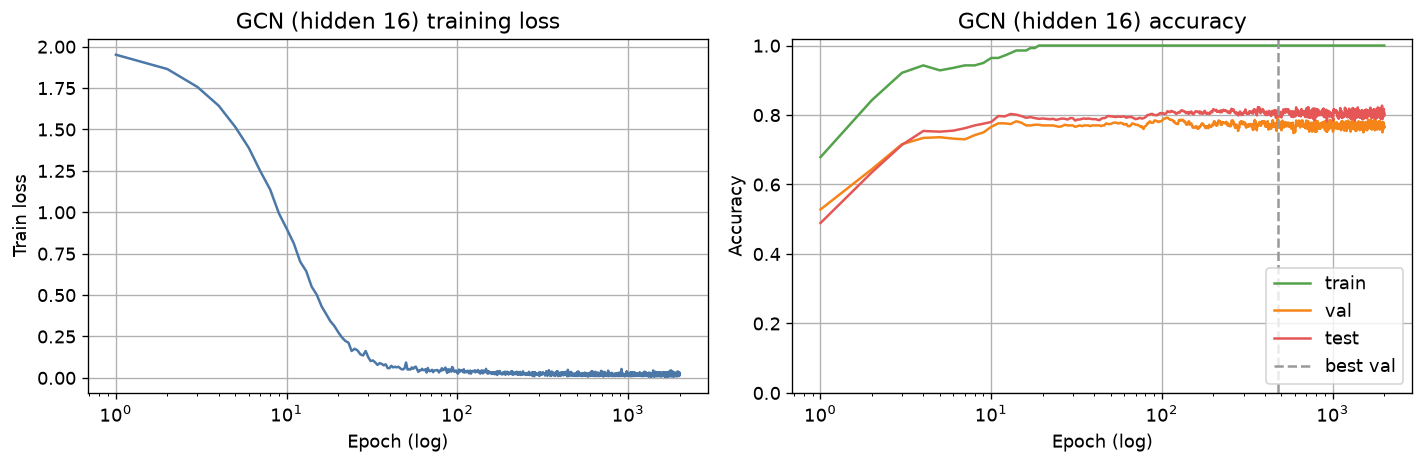

In [7]:
class GCN(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, dropout=0.5):
        super().__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)
        self.dropout = dropout

    def forward(self, data):
        # Mỗi lớp GCNConv gom thông tin từ hàng xóm trên toàn đồ thị; 2 lớp = 2 vòng message passing.
        x, edge_index = data.x, data.edge_index
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        return x


def fit_node_classifier(model, data, lr=0.01, weight_decay=5e-4, epochs=200, patience=None):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    hist = []
    best_val, best_test, best_epoch, wait = -1.0, 0.0, 0, 0
    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()
        out = model(data)
        loss = F.cross_entropy(out[data.train_mask], data.y[data.train_mask])
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            pred = model(data).argmax(dim=1)
        accs = [float((pred[m] == data.y[m]).float().mean()) for m in (data.train_mask, data.val_mask, data.test_mask)]
        hist.append([epoch, float(loss)] + accs)
        if accs[1] > best_val:
            best_val, best_test, best_epoch, wait = accs[1], accs[2], epoch, 0
        else:
            wait += 1
        if patience and wait >= patience:
            break
    hist = np.array(hist)
    return {"hist": hist, "best_val": best_val, "test_at_best_val": best_test,
            "best_epoch": best_epoch, "final_test": hist[-1, 4]}


data = data_cora
set_seed(0)
model = GCN(cora.num_node_features, 16, cora.num_classes).to(device)
t0 = time.perf_counter()
res = fit_node_classifier(model, data, epochs=2000)
print(f"2000 epochs in {time.perf_counter() - t0:.1f}s")
for ep in (20, 50, 100, 200, 500, 1000, 2000):
    _, loss, tr, va, te = res["hist"][ep - 1]
    print(f"Epoch {ep:04d} | Loss {loss:.3f} | Train {tr:.3f} | Val {va:.3f} | Test {te:.3f}")
print(f"Best val {res['best_val']:.3f} at epoch {res['best_epoch']} -> test@best-val {res['test_at_best_val']:.3f}")

h = res["hist"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(h[:, 0], h[:, 1], color="#4C78A8")
axes[0].set_xscale("log")
axes[0].set_xlabel("Epoch (log)")
axes[0].set_ylabel("Train loss")
axes[0].set_title("GCN (hidden 16) training loss")
for col, name, color in ((2, "train", "#54A24B"), (3, "val", "#F58518"), (4, "test", "#E45756")):
    axes[1].plot(h[:, 0], h[:, col], label=name, color=color)
axes[1].axvline(res["best_epoch"], color="#999999", linestyle="--", label="best val")
axes[1].set_xscale("log")
axes[1].set_xlabel("Epoch (log)")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1.02)
axes[1].set_title("GCN (hidden 16) accuracy")
axes[1].legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "gcn_training_curve.png", bbox_inches="tight")
plt.show()

### Số hidden unit và số epoch

Thử hidden = 8, 16, 64, 256, mỗi cấu hình 5 seed, chạy 500 epoch (lần chạy 2000 epoch ở trên đã cho thấy sau vài trăm epoch không còn gì thay đổi). Báo test ở epoch 50, 200, 500 và test@best-val.

grid done in 356.8s


,test@50,test@200,test@500,test@best-val,best epoch (mean)
hidden,,,,,
8,0.781 ± 0.020,0.786 ± 0.011,0.793 ± 0.011,0.791 ± 0.012,140
16,0.794 ± 0.008,0.807 ± 0.006,0.798 ± 0.004,0.807 ± 0.005,305
64,0.803 ± 0.002,0.807 ± 0.006,0.807 ± 0.006,0.807 ± 0.010,86
256,0.807 ± 0.007,0.807 ± 0.005,0.805 ± 0.008,0.813 ± 0.009,4


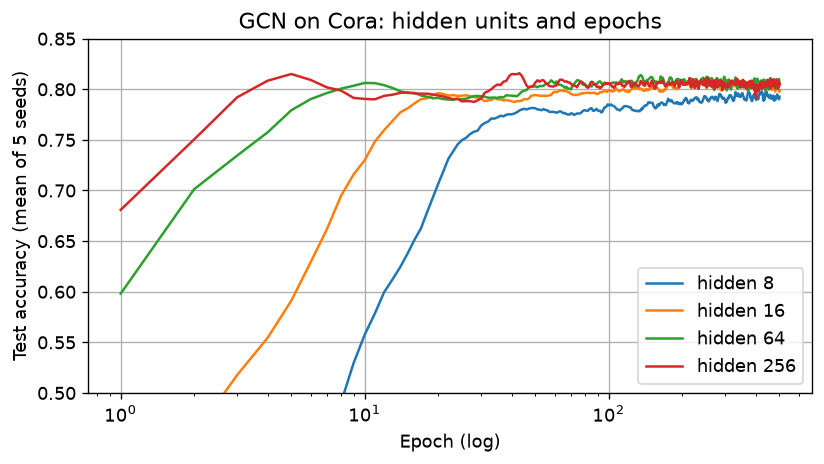

In [8]:
rows = []
curves = {}
t0 = time.perf_counter()
for hidden in (8, 16, 64, 256):
    test_curves = []
    for seed in range(5):
        set_seed(seed)
        m = GCN(cora.num_node_features, hidden, cora.num_classes).to(device)
        r = fit_node_classifier(m, data, epochs=500)
        test_curves.append(r["hist"][:, 4])
        rows.append({"hidden": hidden, "seed": seed,
                     "test@50": r["hist"][49, 4], "test@200": r["hist"][199, 4],
                     "test@500": r["hist"][499, 4], "test@best-val": r["test_at_best_val"],
                     "best epoch": r["best_epoch"]})
    curves[hidden] = np.mean(test_curves, axis=0)
print(f"grid done in {time.perf_counter() - t0:.1f}s")

df_grid = pd.DataFrame(rows)
agg = df_grid.groupby("hidden").agg(["mean", "std"])
cols = ["test@50", "test@200", "test@500", "test@best-val"]
table = pd.DataFrame({c: agg[c]["mean"].map("{:.3f}".format) + " ± " + agg[c]["std"].map("{:.3f}".format) for c in cols})
table["best epoch (mean)"] = agg["best epoch"]["mean"].round(0).astype(int)
display(table)

fig, ax = plt.subplots(figsize=(7, 4))
for hidden, c in curves.items():
    ax.plot(np.arange(1, len(c) + 1), c, label=f"hidden {hidden}")
ax.set_xscale("log")
ax.set_xlabel("Epoch (log)")
ax.set_ylabel("Test accuracy (mean of 5 seeds)")
ax.set_ylim(0.5, 0.85)
ax.set_title("GCN on Cora: hidden units and epochs")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "gcn_hidden_epochs.png", bbox_inches="tight")
plt.show()

## 5. So embedding của Node2Vec và GCN trên Cora

- **GCN:** lấy đầu ra của lớp thứ nhất sau ReLU (16 chiều), từ mô hình hidden 16 ở trên.
- **Node2Vec:** chỉ dùng cạnh, không dùng feature và nhãn. Tham số như ví dụ của PyG cho Cora: 128 chiều, walk dài 20, context 10, mỗi đỉnh 10 walk, p = q = 1. Chạy 40 epoch cho đỡ tốn thời gian trên CPU (khoảng 3 phút).
- **Raw features:** vector bag-of-words 1433 chiều, để làm mốc.

Với mỗi loại vector: chạy logistic regression trên 140 đỉnh train rồi đo trên 1000 đỉnh test (linear probe), và tính silhouette theo nhãn thật bằng khoảng cách cosine.

In [9]:
@torch.no_grad()
def extract_embeddings(model, data):
    model.eval()
    h = model.conv1(data.x, data.edge_index)
    return F.relu(h)


emb_cora = extract_embeddings(model, data).cpu().numpy()

t0 = time.perf_counter()
emb_n2v_cora, loss_n2v_cora = train_node2vec(
    data_cora.edge_index, data_cora.num_nodes,
    embedding_dim=128, walk_length=20, context_size=10, walks_per_node=10,
    num_negative_samples=1, p=1.0, q=1.0, epochs=40, seed=0, log_every=10,
)
print(f"Node2Vec on Cora: {time.perf_counter() - t0:.1f}s")

x_raw = data_cora.x.cpu().numpy()
compare = []
for name, emb in (("Raw features (1433-d)", x_raw), ("Node2Vec (128-d)", emb_n2v_cora), ("GCN hidden (16-d)", emb_cora)):
    compare.append({
        "embedding": name,
        "linear probe test acc": probe_accuracy(emb, y_cora, train_mask, test_mask),
        "silhouette (cosine)": silhouette_score(emb, y_cora, metric="cosine"),
    })
compare.append({"embedding": "GCN end-to-end (hidden 16)",
                "linear probe test acc": res["test_at_best_val"], "silhouette (cosine)": np.nan})
df_compare = pd.DataFrame(compare)
display(df_compare)

Epoch 010 | Loss 1.7127


Epoch 020 | Loss 0.9648


Epoch 030 | Loss 0.8666


Epoch 040 | Loss 0.8424
Node2Vec on Cora: 145.7s


,embedding,linear probe test acc,silhouette (cosine)
0,Raw features (1433-d),0.510,0.009
1,Node2Vec (128-d),0.693,0.077
2,GCN hidden (16-d),0.775,0.351
3,GCN end-to-end (hidden 16),0.815,NaN


silhouette on the 2-D t-SNE map: {'Node2Vec': 0.125, 'GCN': 0.227}


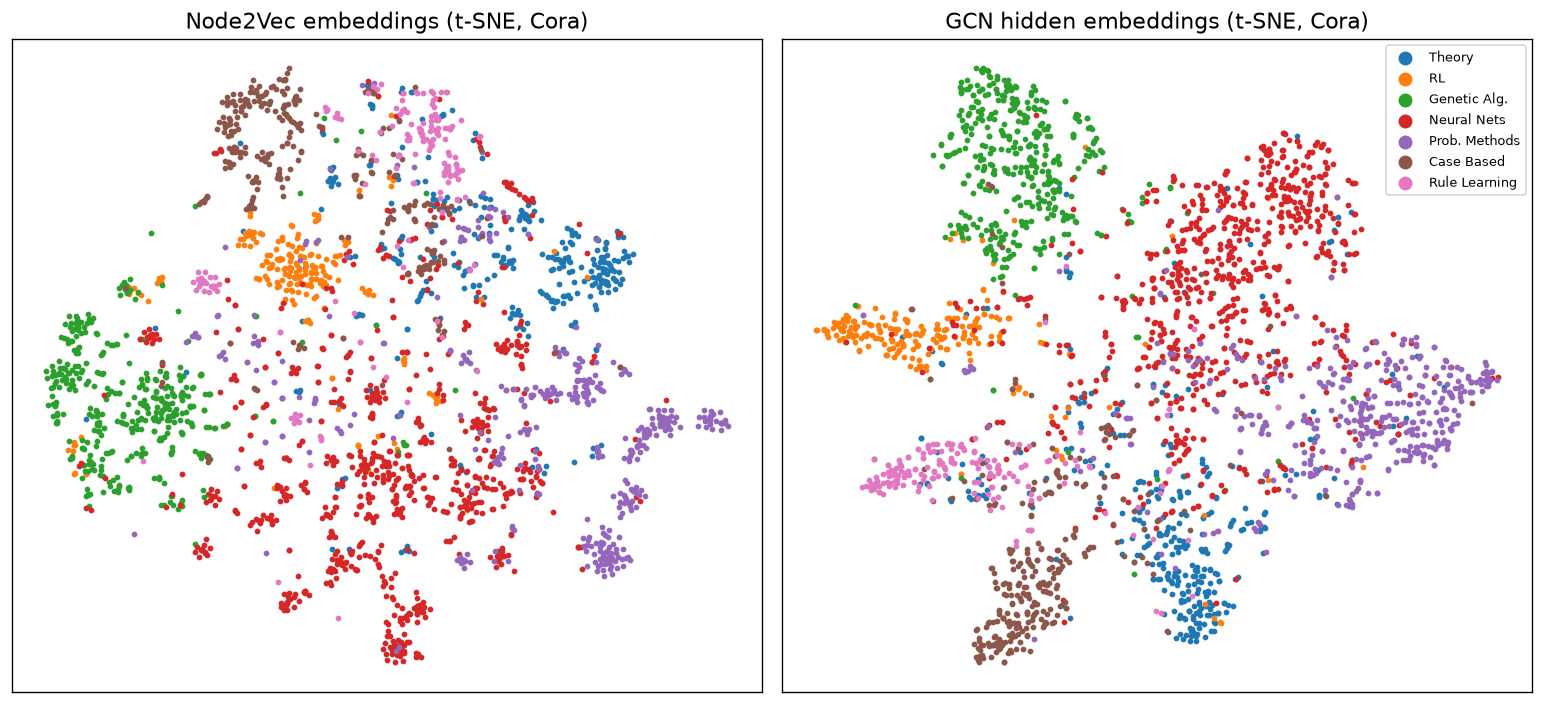

In [10]:
xy_n2v = tsne_2d(emb_n2v_cora)
xy_gcn = tsne_2d(emb_cora)
sil_2d = {"Node2Vec": silhouette_score(xy_n2v, y_cora), "GCN": silhouette_score(xy_gcn, y_cora)}
print("silhouette on the 2-D t-SNE map:", {k: round(v, 3) for k, v in sil_2d.items()})

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
tsne_plot(axes[0], xy_n2v, y_cora, f"Node2Vec embeddings (t-SNE, Cora)", CORA_NAMES)
tsne_plot(axes[1], xy_gcn, y_cora, f"GCN hidden embeddings (t-SNE, Cora)", CORA_NAMES)
axes[1].legend(markerscale=3, fontsize=8, loc="best")
fig.tight_layout()
fig.savefig(FIG / "cora_tsne_node2vec_vs_gcn.png", bbox_inches="tight")
plt.show()

## 6. Node2Vec: đổi p, q (BFS và DFS)

Trong Node2Vec, walk đang đi từ $t$ sang $v$ và chọn bước tiếp theo $x$ với trọng số không chuẩn hóa:

- $1/p$ nếu $x = t$ (quay lại);
- $1$ nếu $x$ là hàng xóm của $t$ (vẫn ở gần $t$);
- $1/q$ nếu $x$ xa $t$ hai bước (đi ra xa).

Như vậy $q > 1$ giữ walk quanh chỗ xuất phát, giống **BFS**, nhìn được cấu trúc cục bộ. $q < 1$ đẩy walk đi xa, giống **DFS**, khám phá rộng hơn. Ở đây giữ p = 1 và đổi q. Walk dài hơn notebook mẫu (dài 20, context 10) để walk có chỗ mà rẽ, và dùng 16 chiều thay cho 64 vì 34 đỉnh không cần nhiều chiều (64 chiều làm silhouette bị nhiễu). Mỗi cấu hình chạy 5 seed rồi lấy trung bình. Các chỉ số thêm:

- $\cos(0, 33)$: độ giống nhau giữa hai thủ lĩnh. Hai đỉnh này cùng vai trò (hub) nhưng ở hai phe đối lập.
- within − across: cosine trung bình của cặp cùng phe trừ cặp khác phe. Càng lớn thì embedding càng phản ánh phe.
- corr(dist): tương quan Spearman giữa cosine của cặp đỉnh và khoảng cách ngắn nhất (đổi dấu). Cao nghĩa là embedding giữ được ai gần ai (homophily).
- corr(role): tương quan Spearman giữa cosine và độ giống nhau về bậc ($-\lvert\log k_u - \log k_v\rvert$). Cao nghĩa là embedding gom các đỉnh cùng vai trò (structural equivalence), kể cả khi chúng ở xa nhau.

Mean over 5 seeds:


,silhouette(club),logreg acc,KMeans ARI,"cos(0,33)",within - across,corr(dist),corr(role)
setting,,,,,,,
"DFS-like (p=1, q=0.25)",0.233,0.966,0.794,0.326,0.269,0.690,0.007
"Uniform (p=1, q=1)",0.246,0.966,0.839,0.328,0.285,0.696,0.005
"BFS-like (p=1, q=4)",0.267,0.966,0.882,0.144,0.317,0.709,0.017


Std over 5 seeds:


,silhouette(club),logreg acc,KMeans ARI,"cos(0,33)",within - across,corr(dist),corr(role)
setting,,,,,,,
"DFS-like (p=1, q=0.25)",0.021,0.013,0.049,0.093,0.027,0.032,0.017
"Uniform (p=1, q=1)",0.018,0.024,0.102,0.101,0.023,0.026,0.015
"BFS-like (p=1, q=4)",0.021,0.013,0.000,0.058,0.030,0.019,0.018


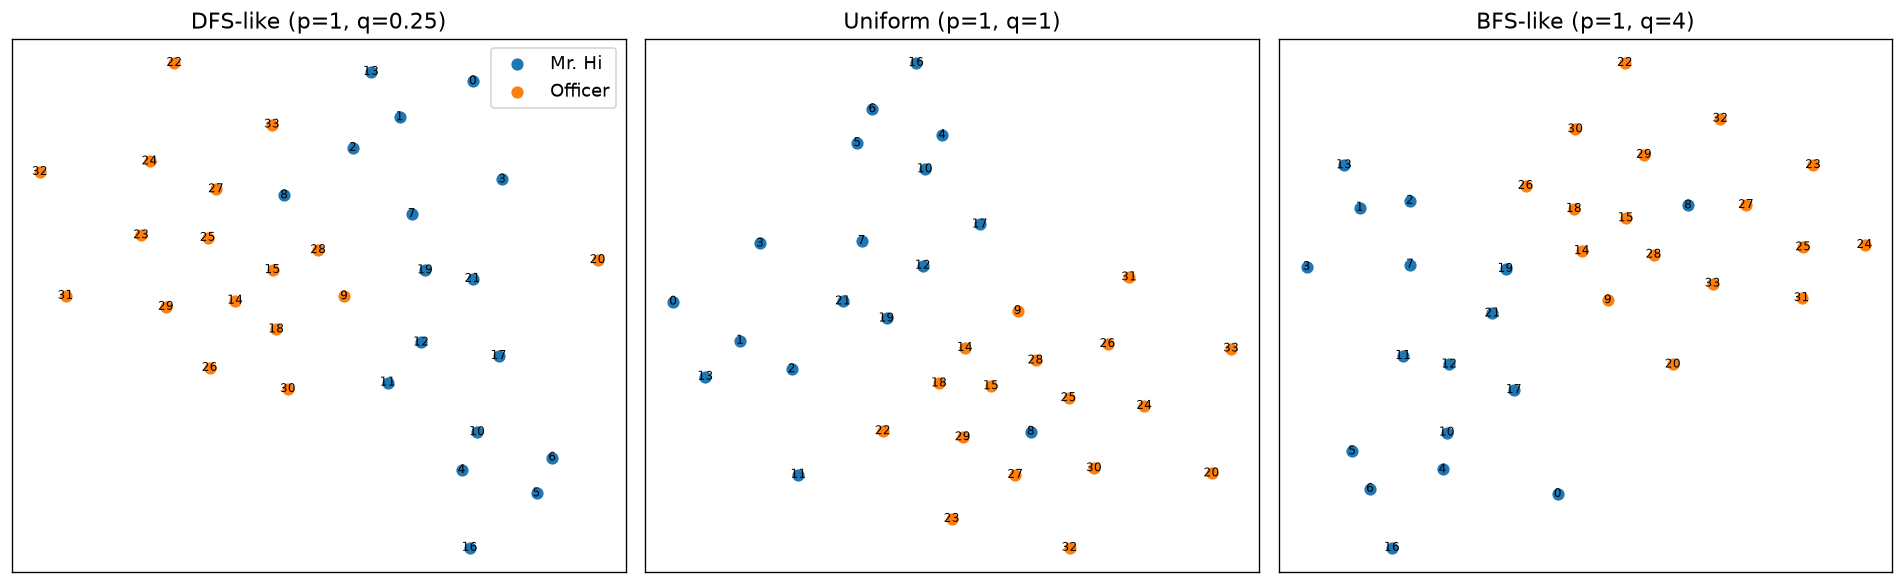

In [11]:
PQ = [("DFS-like (p=1, q=0.25)", 1.0, 0.25), ("Uniform (p=1, q=1)", 1.0, 1.0), ("BFS-like (p=1, q=4)", 1.0, 4.0)]
same = club[:, None] == club[None, :]
off = ~np.eye(34, dtype=bool)
iu = np.triu_indices(34, 1)
G_nx = nx.karate_club_graph()
sp_len = dict(nx.all_pairs_shortest_path_length(G_nx))
DIST = np.array([[sp_len[i][j] for j in range(34)] for i in range(34)])
deg_k = np.array([G_nx.degree(i) for i in range(34)])
ROLE = -np.abs(np.log(deg_k)[:, None] - np.log(deg_k)[None, :])


def cos_matrix(z):
    zn = z / np.linalg.norm(z, axis=1, keepdims=True)
    return zn @ zn.T


pq_rows = []
pq_emb = {}
for label, p, q in PQ:
    for seed in range(5):
        z, _ = train_node2vec(data_karate.edge_index, 34, embedding_dim=16, walk_length=20, context_size=10,
                              walks_per_node=5, num_negative_samples=5, p=p, q=q, epochs=50, batch_size=8, seed=seed)
        if seed == 0:
            pq_emb[label] = z
        sil, acc, ari = karate_metrics(z, seed)
        C = cos_matrix(z)
        pq_rows.append({"setting": label, "seed": seed, "silhouette(club)": sil, "logreg acc": acc,
                        "KMeans ARI": ari, "cos(0,33)": C[0, 33],
                        "within - across": C[same & off].mean() - C[~same].mean(),
                        "corr(dist)": spearmanr(C[iu], -DIST[iu])[0], "corr(role)": spearmanr(C[iu], ROLE[iu])[0]})
df_pq = pd.DataFrame(pq_rows)
pq_mean = df_pq.drop(columns="seed").groupby("setting", sort=False).mean().round(3)
pq_std = df_pq.drop(columns="seed").groupby("setting", sort=False).std().round(3)
print("Mean over 5 seeds:")
display(pq_mean)
print("Std over 5 seeds:")
display(pq_std)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (label, p, q) in zip(axes, PQ):
    tsne_plot(ax, tsne_2d(pq_emb[label], perplexity=10), club, label, CLUB_NAMES, annotate=True)
axes[0].legend()
fig.tight_layout()
fig.savefig(FIG / "karate_node2vec_pq.png", bbox_inches="tight")
plt.show()

## 7. (Optional) Đồ thị k-NN từ embedding

Với mỗi loại vector, nối mỗi đỉnh với k = 4 đỉnh giống nó nhất theo cosine (Cora có bậc trung bình khoảng 3.9), rồi so với đồ thị trích dẫn gốc:

- **overlap / precision:** tỉ lệ cạnh k-NN có trong đồ thị gốc;
- **recall:** tỉ lệ cạnh gốc được k-NN tìm lại;
- **homophily:** tỉ lệ cạnh nối hai bài cùng chủ đề.

In [12]:
def knn_edges(emb, k=4):
    zn = emb / np.maximum(np.linalg.norm(emb, axis=1, keepdims=True), 1e-12)
    S = zn @ zn.T
    np.fill_diagonal(S, -np.inf)
    nbrs = np.argpartition(-S, k, axis=1)[:, :k]
    return {(min(i, j), max(i, j)) for i in range(len(emb)) for j in nbrs[i]}


ei = data_cora.edge_index.cpu().numpy()
orig = {(min(a, b), max(a, b)) for a, b in zip(ei[0], ei[1]) if a != b}


def homophily(edges):
    e = np.array(list(edges))
    return float(np.mean(y_cora[e[:, 0]] == y_cora[e[:, 1]]))


knn_rows = [{"graph": "original citation graph", "#edges": len(orig), "precision": 1.0, "recall": 1.0,
             "homophily": homophily(orig)}]
for name, emb in (("k-NN on raw features", x_raw), ("k-NN on Node2Vec", emb_n2v_cora), ("k-NN on GCN hidden", emb_cora)):
    E = knn_edges(emb, k=4)
    inter = len(E & orig)
    knn_rows.append({"graph": name, "#edges": len(E), "precision": inter / len(E),
                     "recall": inter / len(orig), "homophily": homophily(E)})
df_knn = pd.DataFrame(knn_rows)
display(df_knn)

,graph,#edges,precision,recall,homophily
0,original citation graph,5278,1.000,1.000,0.810
1,k-NN on raw features,8430,0.093,0.149,0.581
2,k-NN on Node2Vec,7863,0.388,0.579,0.778
3,k-NN on GCN hidden,7633,0.170,0.246,0.763


## 8. Optional extensions

### 8a. GraphSAGE và GAT so với GCN

Cùng khung train, 5 seed, tối đa 500 epoch, dừng sớm khi val không tăng trong 100 epoch, báo test@best-val. GAT dùng cấu hình hay gặp cho Cora: 8 head × 8 chiều, dropout 0.6, ELU, lr 0.005.

In [13]:
class SAGE(torch.nn.Module):
    def __init__(self, in_c, hid, out_c, dropout=0.5):
        super().__init__()
        self.conv1, self.conv2, self.dropout = SAGEConv(in_c, hid), SAGEConv(hid, out_c), dropout

    def forward(self, data):
        x = F.relu(self.conv1(data.x, data.edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.conv2(x, data.edge_index)


class GAT(torch.nn.Module):
    def __init__(self, in_c, hid, out_c, heads=8, dropout=0.6):
        super().__init__()
        self.conv1 = GATConv(in_c, hid, heads=heads, dropout=dropout)
        self.conv2 = GATConv(hid * heads, out_c, heads=1, dropout=dropout)
        self.dropout = dropout

    def forward(self, data):
        x = F.dropout(data.x, p=self.dropout, training=self.training)
        x = F.elu(self.conv1(x, data.edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.conv2(x, data.edge_index)


ARCHS = {
    "GCN (16)": (lambda: GCN(cora.num_node_features, 16, cora.num_classes), 0.01),
    "GraphSAGE (16)": (lambda: SAGE(cora.num_node_features, 16, cora.num_classes), 0.01),
    "GAT (8x8 heads)": (lambda: GAT(cora.num_node_features, 8, cora.num_classes), 0.005),
}
arch_rows = []
for name, (make, lr) in ARCHS.items():
    t0 = time.perf_counter()
    for seed in range(5):
        set_seed(seed)
        r = fit_node_classifier(make().to(device), data, lr=lr, epochs=500, patience=100)
        arch_rows.append({"model": name, "seed": seed, "test@best-val": r["test_at_best_val"],
                          "best epoch": r["best_epoch"]})
    print(f"{name}: {time.perf_counter() - t0:.1f}s")
df_arch = pd.DataFrame(arch_rows).drop(columns="seed").groupby("model", sort=False).agg(["mean", "std"]).round(3)
display(df_arch)

GCN (16): 18.9s


GraphSAGE (16): 116.0s


GAT (8x8 heads): 107.9s


test@best-val        best epoch         
                         mean    std       mean      std
model                                                   
GCN (16)                0.803  0.003      122.8  129.880
GraphSAGE (16)          0.801  0.009      181.6  138.139
GAT (8x8 heads)         0.812  0.008       63.8   51.857

### 8b. Dropout và learning rate của GCN

GCN hidden 16, 3 seed, tối đa 500 epoch với dừng sớm như trên.

In [14]:
hp_rows = []
for dropout in (0.0, 0.5, 0.8):
    for lr in (0.001, 0.01, 0.1):
        accs = []
        for seed in range(3):
            set_seed(seed)
            r = fit_node_classifier(GCN(cora.num_node_features, 16, cora.num_classes, dropout=dropout).to(device),
                                    data, lr=lr, epochs=500, patience=100)
            accs.append(r["test_at_best_val"])
        hp_rows.append({"dropout": dropout, "lr": lr, "test@best-val": np.mean(accs)})
display(pd.DataFrame(hp_rows).pivot(index="dropout", columns="lr", values="test@best-val").round(3))

lr,0.001,0.010,0.100
dropout,,,
0.0,0.789,0.803,0.810
0.5,0.795,0.803,0.800
0.8,0.800,0.806,0.803


### 8c. Link prediction bằng embedding trên ego-Facebook

- Giấu ngẫu nhiên 10% cạnh làm test dương, lấy cùng số cặp không có cạnh làm test âm.
- Train Node2Vec (64 chiều, walk 20, context 10, 10 walk mỗi đỉnh, 20 epoch) trên đồ thị train.
- Đặc trưng cạnh từ $z_u, z_v$: Hadamard $z_u \odot z_v$, L1 $\lvert z_u - z_v\rvert$, L2 $(z_u - z_v)^2$. Logistic regression train trên 10000 cạnh train cộng 10000 cặp âm khác.
- So với cosine của hai embedding (không cần train) và với các heuristic ở Lab 6a (CN, Jaccard, Adamic-Adar, RA), tính trên cùng đồ thị train.

In [15]:
fb_candidates = [
    LAB.parent / "Lab1_2" / "facebook_combined.txt",
    LAB / "facebook_combined.txt",
    Path.cwd() / "facebook_combined.txt",
]
fb_path = next(path for path in fb_candidates if path.exists())
print(f"Đọc {fb_path}")
Gfb = nx.read_edgelist(fb_path, nodetype=int)
N_fb = Gfb.number_of_nodes()
print("Loaded:", N_fb, "nodes,", Gfb.number_of_edges(), "edges")

rng = random.Random(42)
fb_edges = list(Gfb.edges())
rng.shuffle(fb_edges)
n_test = int(0.10 * len(fb_edges))
test_pos = fb_edges[:n_test]
train_pos = fb_edges[n_test:]
G_train = nx.Graph()
G_train.add_nodes_from(Gfb.nodes())
G_train.add_edges_from(train_pos)


def sample_non_edges(n, exclude):
    out = []
    while len(out) < n:
        u, v = rng.randrange(N_fb), rng.randrange(N_fb)
        key = (min(u, v), max(u, v))
        if u == v or Gfb.has_edge(u, v) or key in exclude:
            continue
        exclude.add(key)
        out.append(key)
    return out


used = set()
test_neg = sample_non_edges(n_test, used)
clf_pos = rng.sample(train_pos, 10000)
clf_neg = sample_non_edges(10000, used)
print(f"train edges {len(train_pos)}, test {len(test_pos)} pos + {len(test_neg)} neg, isolated nodes in train: {sum(1 for n in G_train if G_train.degree(n) == 0)}")

tr_ei = torch.tensor(np.array(train_pos).T, dtype=torch.long)
tr_ei = torch.cat([tr_ei, tr_ei.flip(0)], dim=1)
t0 = time.perf_counter()
z_fb, loss_fb = train_node2vec(tr_ei, N_fb, embedding_dim=64, walk_length=20, context_size=10,
                               walks_per_node=10, num_negative_samples=1, epochs=20, batch_size=256,
                               seed=0, log_every=5)
print(f"Node2Vec on Facebook: {time.perf_counter() - t0:.1f}s")

Đọc d:\Study\IS353\BT\Lab1_2\facebook_combined.txt


Loaded: 4039 nodes, 88234 edges


train edges 79411, test 8823 pos + 8823 neg, isolated nodes in train: 7


Epoch 005 | Loss 2.3450


Epoch 010 | Loss 1.2722


Epoch 015 | Loss 1.0025


Epoch 020 | Loss 0.9165
Node2Vec on Facebook: 74.0s


In [16]:
def edge_feats(pairs, op):
    a = z_fb[[u for u, _ in pairs]]
    b = z_fb[[v for _, v in pairs]]
    return {"Hadamard": a * b, "L1": np.abs(a - b), "L2": (a - b) ** 2}[op]


X_pairs_tr = clf_pos + clf_neg
y_tr = np.array([1] * len(clf_pos) + [0] * len(clf_neg))
X_pairs_te = test_pos + test_neg
y_te = np.array([1] * len(test_pos) + [0] * len(test_neg))

lp_rows = []
for op in ("Hadamard", "L1", "L2"):
    scaler = StandardScaler().fit(edge_feats(X_pairs_tr, op))
    clf = LogisticRegression(max_iter=3000).fit(scaler.transform(edge_feats(X_pairs_tr, op)), y_tr)
    s = clf.predict_proba(scaler.transform(edge_feats(X_pairs_te, op)))[:, 1]
    lp_rows.append({"method": f"Node2Vec + {op} + LogReg", "AUC": roc_auc_score(y_te, s), "AP": average_precision_score(y_te, s)})

zn = z_fb / np.linalg.norm(z_fb, axis=1, keepdims=True)
s_cos = np.array([zn[u] @ zn[v] for u, v in X_pairs_te])
lp_rows.append({"method": "Node2Vec cosine (no training)", "AUC": roc_auc_score(y_te, s_cos), "AP": average_precision_score(y_te, s_cos)})

for name, fn in (("CN", lambda G, P: [(u, v, len(list(nx.common_neighbors(G, u, v)))) for u, v in P]),
                 ("Jaccard", nx.jaccard_coefficient), ("Adamic-Adar", nx.adamic_adar_index),
                 ("RA", nx.resource_allocation_index)):
    s = np.array([p for _, _, p in fn(G_train, X_pairs_te)])
    lp_rows.append({"method": f"Heuristic {name}", "AUC": roc_auc_score(y_te, s), "AP": average_precision_score(y_te, s)})

df_lp = pd.DataFrame(lp_rows).sort_values("AUC", ascending=False).reset_index(drop=True)
display(df_lp)

,method,AUC,AP
0,Heuristic RA,0.995,0.994
1,Heuristic Adamic-Adar,0.993,0.992
2,Heuristic CN,0.992,0.990
3,Heuristic Jaccard,0.991,0.990
4,Node2Vec + Hadamard + LogReg,0.982,0.976
5,Node2Vec cosine (no training),0.973,0.959
6,Node2Vec + L1 + LogReg,0.776,0.768
7,Node2Vec + L2 + LogReg,0.699,0.697


## 1. Compare Node2Vec vs. GCN embeddings (t-SNE plots). Do you see clearer clusters with GCN on Cora?

### 1. So embedding của Node2Vec và GCN qua t-SNE. GCN trên Cora có cho cụm rõ hơn không?

Có, GCN cho cụm rõ hơn hẳn.

![Cora t-SNE](figures/cora_tsne_node2vec_vs_gcn.png)

| Vector | Linear probe (test acc) | Silhouette theo nhãn (cosine) | Silhouette trên bản đồ t-SNE |
| --- | --- | --- | --- |
| Raw features (1433 chiều) | 0.510 | 0.009 | |
| Node2Vec (128 chiều) | 0.693 | 0.077 | 0.125 |
| GCN hidden (16 chiều) | 0.775 | **0.351** | **0.227** |
| GCN end-to-end | **0.815** | | |

**Nhìn hình.** Bên GCN, mỗi chủ đề thành một vùng lớn liền nhau: Genetic Algorithms (xanh lá) ở góc trên trái, Neural Nets (đỏ) ở giữa trên, RL (cam), Rule Learning (hồng), Case Based (nâu), Theory (xanh dương) và Prob. Methods (tím) tách thành từng vùng riêng. Lẫn nhau chủ yếu ở phần giữa, nơi Neural Nets gặp Theory và Prob. Methods. Bên Node2Vec có nhiều đảo nhỏ rất chặt, thường chỉ một màu, nhưng các đảo cùng màu nằm rải rác khắp bản đồ. Rõ nhất là Neural Nets (lớp lớn nhất, 818 bài): nó vỡ thành hàng chục cụm nhỏ ở nửa dưới, xen với tím và xanh dương.

**Vì sao.** Node2Vec chỉ thấy cạnh trích dẫn. Hai bài gần nhau khi chúng hay cùng xuất hiện trên random walk, tức là ở cùng một vùng nhỏ của đồ thị. Một chủ đề lớn gồm nhiều nhóm bài trích dẫn lẫn nhau nhưng ít trích dẫn sang nhóm khác cùng chủ đề, nên thành nhiều đảo. GCN dùng cả nội dung (bag-of-words) lẫn hàng xóm, và lớp ẩn được train có giám sát để tách 7 lớp. Hai bài cùng chủ đề có từ ngữ giống nhau nên bị kéo lại gần nhau, kể cả khi chúng không trích dẫn nhau.

So sánh này không hoàn toàn công bằng: GCN thấy 140 nhãn train, Node2Vec không thấy nhãn nào. Dù vậy, ba mức probe cho thấy rõ phần đóng góp của từng nguồn: chỉ feature 0.510, chỉ cấu trúc 0.693, cả hai qua GCN 0.775 đến 0.815. Cấu trúc giúp nhiều hơn feature trên Cora, và kết hợp cả hai là tốt nhất.

Trên Karate (tham số như notebook mẫu, 64 chiều), Node2Vec cũng giữ được thông tin phe: logistic regression đoán phe đạt 0.971 (5 fold), KMeans trên vector chuẩn hóa đạt ARI 0.668. Silhouette chỉ 0.034 vì 64 chiều là quá nhiều cho 34 đỉnh, phần lớn chiều chỉ mang nhiễu.

![Karate Node2Vec](figures/karate_node2vec.png)

## 2. Run GCN longer until convergence. Report final test accuracy for GCN. Does increasing hidden units/epochs help?

### 2. Chạy GCN lâu hơn đến khi hội tụ. Báo test accuracy cuối. Tăng hidden unit hay epoch có giúp không?

**Chạy 2000 epoch, hidden 16:**

| Epoch | Loss | Train | Val | Test |
| --- | --- | --- | --- | --- |
| 20 | 0.277 | 1.000 | 0.770 | 0.790 |
| 50 | 0.092 | 1.000 | 0.774 | 0.796 |
| 100 | 0.027 | 1.000 | 0.784 | 0.804 |
| 200 | 0.025 | 1.000 | 0.774 | 0.815 |
| 500 | 0.020 | 1.000 | 0.756 | 0.793 |
| 1000 | 0.018 | 1.000 | 0.762 | 0.798 |
| 2000 | 0.021 | 1.000 | 0.766 | 0.803 |

![GCN training curve](figures/gcn_training_curve.png)

**Test accuracy cuối: 0.803 ở epoch 2000. Chọn theo val tốt nhất (0.794 ở epoch 476) thì test là 0.815.** Con số này khớp với mức 81.5% trong bài báo GCN gốc.

GCN hội tụ rất sớm. Train accuracy lên 1.0 từ khoảng epoch 20, loss phẳng từ khoảng epoch 100. Sau đó val và test chỉ dao động trong khoảng ±1%. Mô hình đã thuộc lòng 140 đỉnh train, dropout và weight decay giữ cho nó không tệ đi, nhưng cũng không còn gì để học thêm. Chạy 20000 epoch như notebook mẫu không có lợi gì.

**Hidden unit và epoch** (5 seed, mean ± std):

| Hidden | test@50 | test@200 | test@500 | test@best-val |
| --- | --- | --- | --- | --- |
| 8 | 0.781 ± 0.020 | 0.786 ± 0.011 | 0.793 ± 0.011 | 0.791 ± 0.012 |
| 16 | 0.794 ± 0.008 | 0.807 ± 0.006 | 0.798 ± 0.004 | 0.807 ± 0.005 |
| 64 | 0.803 ± 0.002 | 0.807 ± 0.006 | 0.807 ± 0.006 | 0.807 ± 0.010 |
| 256 | 0.807 ± 0.007 | 0.807 ± 0.005 | 0.805 ± 0.008 | 0.813 ± 0.009 |

![Hidden and epochs](figures/gcn_hidden_epochs.png)

- **Hidden unit:** từ 8 lên 16 thì có lợi (+1.6 điểm). Từ 16 lên 64 hay 256 thì gần như không đổi (0.807 → 0.813), chênh lệch nằm trong một độ lệch chuẩn. Mô hình rộng học nhanh hơn: hidden 256 đạt 0.807 ngay ở epoch 50, và val tốt nhất của nó trung bình rơi vào epoch thứ 4, sau đó chỉ còn overfit.
- **Epoch:** từ 50 lên 200 có lợi với mô hình hẹp (hidden 16: 0.794 → 0.807), không có lợi với mô hình rộng. Từ 200 lên 500 không còn lợi, có khi còn giảm nhẹ.

Giới hạn ở đây là dữ liệu có nhãn (140 đỉnh), không phải sức chứa của mô hình hay thời gian train. Muốn tăng thật sự thì phải đổi kiến trúc (GAT ở câu 5 lên 0.812) hoặc thêm nhãn, chứ tăng hidden hay epoch không giúp.

## 3. Change Node2Vec p,q to bias BFS/DFS. Describe effect on the embedding plot.

### 3. Đổi p, q của Node2Vec để thiên về BFS hoặc DFS. Mô tả ảnh hưởng lên biểu đồ embedding.

Karate Club, p = 1, đổi q, 16 chiều, walk dài 20, context 10. Trung bình 5 seed:

| Cấu hình | Silhouette (phe) | KMeans ARI | within − across | cos(0, 33) | corr(dist) | corr(role) |
| --- | --- | --- | --- | --- | --- | --- |
| DFS (q = 0.25) | 0.233 | 0.794 | 0.269 | 0.326 | 0.690 | 0.007 |
| Uniform (q = 1) | 0.246 | 0.839 | 0.285 | 0.328 | 0.696 | 0.005 |
| BFS (q = 4) | **0.267** | **0.882** | **0.317** | **0.144** | **0.709** | 0.017 |

![Node2Vec p, q](figures/karate_node2vec_pq.png)

**BFS (q = 4)** cho hai phe tách rõ nhất trên hình: Mr. Hi ở nửa trái, Officer ở nửa phải. Đỉnh 0 nằm hẳn trong nhóm của mình ở góc dưới, đỉnh 33 nằm giữa các Officer. KMeans tách đúng phe với ARI 0.882 ở cả 5 seed (std = 0). Với q lớn, walk quanh quẩn gần đỉnh xuất phát, nên ngữ cảnh của một đỉnh chủ yếu là hàng xóm gần. Ở Karate, hàng xóm gần hầu hết cùng phe. Kết quả là các cụm chặt hơn, và hai thủ lĩnh 0, 33 bị đẩy xa nhau (cosine 0.144).

**DFS (q = 0.25)** vẫn tách được hai phe nhưng lỏng hơn. Ở giữa hình có vùng lẫn: đỉnh 8 (Mr. Hi) nằm sát các Officer 27, 28, đỉnh 20 bị đẩy ra rìa. Với q nhỏ, walk đi xa, nhiều walk vượt qua các cầu giữa hai phe (ví dụ 2–32, 8–33, 13–33, 0–31), nên ngữ cảnh chứa đỉnh của cả hai phe. Hai thủ lĩnh xuất hiện chung trên nhiều walk dài, nên giống nhau hơn (cosine 0.326, gần gấp đôi BFS).

Uniform (q = 1) nằm giữa hai đầu trên mọi chỉ số.

Hai nhận xét thêm:

- Khác biệt có thật nhưng không lớn (ARI 0.79 so với 0.88). Karate có đường kính 5, nên walk dài 20 kiểu nào cũng đi được gần hết đồ thị. Logistic regression đoán phe đạt 0.966 ở cả ba cấu hình: thông tin phe luôn có trong embedding, chỉ khác ở chỗ nó có tạo thành cụm hình học rõ hay không.
- corr(role) xấp xỉ 0 ở cả ba cấu hình. Nghĩa là kể cả BFS cũng không gom các đỉnh cùng vai trò (ví dụ hai hub 0 và 33, hay các lá bậc 1 và 2) khi chúng ở xa nhau. Người ta thường nói "BFS bắt structural equivalence", nhưng ở đây không thấy: skip-gram trên walk vẫn chủ yếu học ai ở gần ai (corr(dist) khoảng 0.7). Muốn embedding theo vai trò thì cần phương pháp khác, như struc2vec, hoặc thêm feature bậc.

## 4. (Optional) Build a k-NN graph using cosine similarity on embeddings and compare to original edges.

### 4. (Tùy chọn) Dựng đồ thị k-NN theo cosine trên embedding và so với cạnh gốc.

k = 4 trên Cora:

| Đồ thị | Số cạnh | Precision (có trong đồ thị gốc) | Recall (cạnh gốc tìm lại được) | Homophily |
| --- | --- | --- | --- | --- |
| Đồ thị trích dẫn gốc | 5278 | 1.000 | 1.000 | 0.810 |
| k-NN trên raw features | 8430 | 0.093 | 0.149 | 0.581 |
| k-NN trên Node2Vec | 7863 | **0.388** | **0.579** | 0.778 |
| k-NN trên GCN hidden | 7633 | 0.170 | 0.246 | 0.763 |

- **Node2Vec tái tạo đồ thị gốc tốt nhất:** tìm lại 58% cạnh trích dẫn, và 39% cạnh k-NN là cạnh thật. Đúng mục tiêu train của nó: các đỉnh hay cùng xuất hiện trên walk, tức hàng xóm thật, phải có vector gần nhau. Đồ thị k-NN này giống một bản làm mượt của đồ thị gốc. Phần cạnh "sai" thường là hàng xóm bậc 2, nên homophily vẫn cao (0.778).
- **GCN giữ chủ đề, không giữ cạnh:** homophily 0.763, gần bằng đồ thị gốc, nhưng chỉ 17% cạnh trùng. Hàng xóm gần nhất trong không gian GCN là bài cùng chủ đề và cùng kiểu từ ngữ, nhưng thường không trích dẫn nhau. Embedding 16 chiều được train để phân lớp, nên nó nén mất chi tiết ai trích dẫn ai.
- **Raw features yếu ở cả hai mặt:** chỉ 9% trùng và homophily 0.581. Bag-of-words 1433 chiều rất thưa, nên cosine giữa hai bài nhiễu.

Hai đồ thị k-NN dùng được cho hai việc khác nhau. k-NN từ Node2Vec gợi ý cạnh còn thiếu, tức link prediction. k-NN từ GCN gợi ý nối những bài cùng chủ đề, có thể dùng để thêm cạnh khi đồ thị gốc quá thưa (graph structure learning).

## 5. (Optional) Extensions

### 5. (Tùy chọn) Phần mở rộng

**GraphSAGE và GAT so với GCN** (5 seed, tối đa 500 epoch, dừng sớm sau 100 epoch không cải thiện):

| Mô hình | test@best-val | Thời gian 5 seed |
| --- | --- | --- |
| GCN (16) | 0.803 ± 0.003 | 19 s |
| GraphSAGE (16) | 0.801 ± 0.009 | 116 s |
| GAT (8 head × 8) | **0.812 ± 0.008** | 108 s |

GAT tốt nhất, hơn GCN khoảng 1 điểm, cùng hướng với kết quả trong bài báo GAT (83.0% so với 81.5%). GAT học trọng số riêng cho từng hàng xóm, nên giảm được ảnh hưởng của những trích dẫn sang chủ đề khác. Đổi lại, nó chậm hơn khoảng 5 lần. GraphSAGE không hơn GCN trên Cora. Điểm mạnh của SAGE là học inductive và lấy mẫu hàng xóm trên đồ thị lớn, mà Cora nhỏ, transductive, nên không dùng tới.

**Dropout × learning rate của GCN** (3 seed, test@best-val):

| dropout \ lr | 0.001 | 0.01 | 0.1 |
| --- | --- | --- | --- |
| 0.0 | 0.789 | 0.803 | 0.810 |
| 0.5 | 0.795 | 0.803 | 0.800 |
| 0.8 | 0.800 | 0.806 | 0.803 |

Mọi ô nằm trong khoảng 0.79 đến 0.81. GCN trên Cora khá ít nhạy với hai tham số này. Chỉ lr = 0.001 thấp hơn một chút, vì nó học chậm và bị dừng sớm trước khi đạt mức tốt nhất. Cũng ở lr này, dropout cao hơn giúp được một chút (0.789 → 0.800).

**Link prediction bằng embedding trên ego-Facebook** (giấu 10% cạnh, 8823 cặp dương + 8823 cặp âm):

| Phương pháp | AUC | AP |
| --- | --- | --- |
| Heuristic RA | **0.995** | **0.994** |
| Heuristic Adamic-Adar | 0.993 | 0.992 |
| Heuristic CN | 0.992 | 0.990 |
| Heuristic Jaccard | 0.991 | 0.990 |
| Node2Vec + Hadamard + LogReg | 0.982 | 0.976 |
| Node2Vec cosine (không train) | 0.973 | 0.959 |
| Node2Vec + L1 + LogReg | 0.776 | 0.768 |
| Node2Vec + L2 + LogReg | 0.699 | 0.697 |

- Hadamard là toán tử tốt nhất, giống kết luận của bài báo node2vec. Logistic regression trên $z_u \odot z_v$ thực chất học một tích vô hướng có trọng số, khớp với cách skip-gram đo độ gần: tích vô hướng của hai embedding. L1 và L2 chỉ đo hai vector khác nhau bao nhiêu trên từng chiều, mất thông tin hướng, nên kém hẳn.
- Embedding vẫn thua heuristic local, giống kết luận của Lab 6a: ego-Facebook dày và nhiều tam giác, nên RA đã gần như hoàn hảo. Chất lượng embedding phụ thuộc mạnh vào việc train đủ hay chưa. Lần chạy thử với 5 epoch (loss vẫn đang giảm) chỉ đạt AUC khoảng 0.79. 20 epoch thì lên 0.982.
- File `facebook_combined.txt` không có nhãn cho đỉnh, nên ý "dùng Facebook với feature tự tạo (bậc, clustering) để phân loại đỉnh" không làm được trên dữ liệu này. Facebook được dùng cho bài toán link prediction ở trên.